# PHYG 2026 — TME 2
### Phylogénie et génomique comparative
## Parsimony, genome rearrangements and character-based trees

| | |
|---|---|
| **Student 1** | _surname, first name_ |
| **Student 2** | _surname, first name_ |
| **Date** | _dd/mm/yyyy_ |

Léon Faure — <leon.faure@sorbonne-universite.fr>
Course materials: <https://github.com/leonfaure/PHYG2026>

> ### Overview
>
> In this session you leave distances between sequences behind. You score trees
> by **parsimony**, by hand and with PHYLIP's `pars`; you compare whole
> **genomes** through the rearrangements that separate them and build trees from
> rearrangement distances; and you reconstruct trees from **morphological
> characters**, where convergent evolution can mislead.
>
> **Learning items**:
> - explain the principle of maximum parsimony and the small / large parsimony problems;
> - run the Fitch and Sankoff algorithms on a fixed tree;
> - read a whole-genome comparison and compute a reversal distance;
> - recognise homoplasy (convergence) in character data and its effect on a tree;
> - judge whether a reconstructed tree is correct against an accepted phylogeny.

> ### About these sessions
>
> The TMEs account for only **10% of the final grade**. They are there to help you
> understand the course material and to get hands-on experience with real
> problems — not to produce a perfect report. Please do the thinking yourself: it
> is **discouraged to let an AI do the work for you**. Using one to help you
> *understand* a concept, a tool or an error message is fine; handing it the
> questions and pasting back the answers defeats the purpose.

---

### How to hand this in

**Deadline: 26 November.** Work in groups of **at most two students**; you may
also work alone.

1. Fill in your names in the table above.
2. Answer **every** question — in the `Your answer` markdown cells for written
   answers, in the `TODO` code cells for code. Where a question only asks you to
   display something, the figure itself is the answer.
3. **Restart the kernel and run all cells** (`Kernel → Restart Kernel and Run All Cells`)
   and check it runs top to bottom without errors.
4. Rename the file `SURNAME1_SURNAME2_TME2.ipynb` and e-mail it to
   <leon.faure@sorbonne-universite.fr> with the subject `[PHYG] TME2`.

Send **the notebook only** — no PDF, no archive. Figures produced by your code,
and the pictures you embed with `embed_image()`, are stored inside the `.ipynb`
as cell outputs, so they travel with it.

***
## Toolbox

**Run the cell below first.** It is provided — you do not need to modify it, but
do read the function signatures, you will be using them throughout the notebook.

What is new since TME1:

- `parsimony_tree()` runs PHYLIP's **`pars`** on a table of 0/1 characters, and
  `exhaustive_parsimony()` scores every possible tree instead (small data only);
- `small_parsimony()` scores a *fixed* tree (Fitch or Sankoff), to check your
  hand computation;
- `reverse()`, `breakpoints()` and `reversal_distance()` work on signed
  permutations of genome blocks;
- `read_phylip_matrix()` reads a distance matrix from a file;
- `compare_topologies()` tells you how many groupings two trees share.

`build_tree()`, `show_tree()`, `sister_group()` and `embed_image()` are the TME1
functions, unchanged — `embed_image()` now also accepts SVG files.

> **If something looks wrong**, re-run this cell, then the cell that failed. If it
> still fails, read the last line of the error message — it usually names the file
> that could not be found or the program that is missing (`pixi run selftest`
> checks the programs).

In [ ]:
import io, itertools, re, subprocess, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio import Phylo
from Bio.Phylo.TreeConstruction import DistanceMatrix
from IPython.display import HTML as _HTML, Image as _Image, display

plt.rcParams["figure.dpi"] = 110


# --------------------------------------------------------------------------
# PHYLIP plumbing. You do not need to read this part.
#
# PHYLIP identifies taxa by exactly ten characters, which long names would
# break, so we hand PHYLIP unique tokens and put the real names back afterwards. PHYLIP also
# reads and writes fixed filenames in the current directory, so every run gets
# a private temporary directory.
# --------------------------------------------------------------------------

def _tokens(names):
    return {name: "SEQ%07d" % i for i, name in enumerate(names)}


def _run_phylip(program, infile_text, keystrokes):
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        (tmp / "infile").write_text(infile_text)
        proc = subprocess.run([program], input=keystrokes, cwd=tmp,
                              text=True, capture_output=True, timeout=3600)
        outfile, outtree = tmp / "outfile", tmp / "outtree"
        if not outfile.exists():
            raise RuntimeError("%s did not produce an outfile.\n\n%s"
                               % (program, (proc.stdout or proc.stderr)[-2000:]))
        return outfile.read_text(), (outtree.read_text() if outtree.exists() else None)


def _wrap(prefix, values, per_line=6):
    out, chunk = [], [values[i:i + per_line] for i in range(0, len(values), per_line)]
    for i, part in enumerate(chunk):
        head = prefix if i == 0 else " " * len(prefix)
        out.append(head + "".join("%12.6f" % v for v in part))
    return out


def _read_newicks(text, back):
    trees = []
    for chunk in text.replace("\n", "").split(";"):
        if chunk.strip():
            tree = Phylo.read(io.StringIO(chunk + ";"), "newick")
            for tip in tree.get_terminals():
                tip.name = back.get((tip.name or "").strip(), tip.name)
            trees.append(tree)
    return trees


# --------------------------------------------------------------------------
# Exercise 1 — small parsimony on a fixed tree
# --------------------------------------------------------------------------

def small_parsimony(newick, sequences, cost=None):
    """Parsimony score of a *rooted* tree, site by site (Sankoff's algorithm).

    newick    : the tree, e.g. "((A,B),(C,D));"
    sequences : {"A": "ATCCTG", ...}
    cost      : substitution cost table as a pandas DataFrame (rows = from,
                columns = to). None means every change costs 1, which is what
                Fitch's algorithm counts.
    Returns a table with one row per site and the total. It gives you the score
    to check your hand computation against — not the steps.
    """
    tree = Phylo.read(io.StringIO(newick), "newick")
    states = sorted(set("".join(sequences.values())))
    if cost is None:
        cost = pd.DataFrame([[0 if a == b else 1 for b in states] for a in states],
                            index=states, columns=states)
    states = list(cost.index)
    length = len(next(iter(sequences.values())))
    rows = []
    for site in range(length):
        def score(clade):
            if clade.is_terminal():
                ch = sequences[clade.name][site]
                return {s: (0 if s == ch else np.inf) for s in states}
            kids = [score(c) for c in clade.clades]
            return {s: sum(min(k[t] + cost.loc[s, t] for t in states) for k in kids)
                    for s in states}
        root = score(tree.root)
        rows.append({"site": site + 1,
                     "column": "".join(sequences[n][site] for n in sequences),
                     "score": min(root.values())})
    table = pd.DataFrame(rows).set_index("site")
    table.loc["total"] = ["", table["score"].sum()]
    return table


# --------------------------------------------------------------------------
# Exercise 2 — genome rearrangements
# --------------------------------------------------------------------------

def reverse(perm, i, j):
    """Apply one reversal to a signed permutation: positions i..j (1-based,
    inclusive) are put in reverse order and their signs flipped."""
    perm = list(perm)
    i, j = min(i, j), max(i, j)
    return perm[:i - 1] + [-x for x in reversed(perm[i - 1:j])] + perm[j:]


def breakpoints(perm):
    """Breakpoints of a signed permutation, framed by 0 and n+1: every
    neighbouring pair (a, b) that is not b = a + 1."""
    framed = [0] + list(perm) + [len(perm) + 1]
    return [(a, b) for a, b in zip(framed, framed[1:]) if b != a + 1]


def reversal_distance(perm):
    """Minimum number of reversals that sort a signed permutation into
    1, 2, ..., n (Hannenhalli & Pevzner 1995: d = n + 1 - c + h + f)."""
    n = len(perm)
    seq = [0]
    for x in perm:
        seq += [2 * x - 1, 2 * x] if x > 0 else [-2 * x, -2 * x - 1]
    seq.append(2 * n + 1)
    if sorted(seq) != list(range(2 * n + 2)):
        raise ValueError("not a signed permutation of 1..%d" % n)
    pos = {v: i for i, v in enumerate(seq)}
    m = len(seq)

    cyc, c = [-1] * m, 0                       # cycles of the breakpoint graph
    for s in range(m):
        if cyc[s] < 0:
            i = s
            while cyc[i] < 0:
                cyc[i] = c
                j = i ^ 1                      # black edge
                cyc[j] = c
                i = pos[seq[j] ^ 1]            # grey edge
            c += 1

    edges = []                                 # grey edges, minus trivial cycles
    for k in range(n + 1):
        a, b = sorted((pos[2 * k], pos[2 * k + 1]))
        if not (b - a == 1 and a % 2 == 0):
            edges.append((a, b, (b - a) % 2 == 0))
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for a, b, _ in edges:
        parent[find(("e", a, b))] = find(("c", cyc[a]))
    for (a1, b1, _), (a2, b2, _) in itertools.combinations(edges, 2):
        if a1 < a2 < b1 < b2 or a2 < a1 < b2 < b1:
            parent[find(("e", a1, b1))] = find(("e", a2, b2))
    oriented = {}
    for a, b, o in edges:
        r = find(("e", a, b))
        oriented[r] = oriented.get(r, False) or o
    label = {}
    for a, b, _ in edges:
        r = find(("e", a, b))
        if not oriented[r]:
            label[a] = label[b] = r
    circ = [label[i] for i in range(m) if i in label]

    def hurdles(s):
        s = [x for i, x in enumerate(s) if i == 0 or x != s[i - 1]]
        if len(s) > 1 and s[0] == s[-1]:
            s.pop()
        return {x for x in set(s) if s.count(x) == 1}
    H = hurdles(circ)
    f = int(len(H) % 2 == 1 and len(H) >= 3 and
            all(hurdles([y for y in circ if y != x]) - H for x in H))
    return n + 1 - c + len(H) + f


def read_permutation(path):
    """A signed permutation stored as whitespace-separated integers."""
    return [int(x) for x in Path(path).read_text().split()]


def read_phylip_matrix(path):
    """Read a square PHYLIP distance matrix (first line: number of taxa)."""
    lines = [l.split() for l in Path(path).read_text().splitlines() if l.strip()]
    n = int(lines[0][0])
    names = [row[0] for row in lines[1:n + 1]]
    full = [[float(x) for x in row[1:n + 1]] for row in lines[1:n + 1]]
    return DistanceMatrix(names=names,
                          matrix=[[full[i][j] for j in range(i + 1)] for i in range(n)])


# --------------------------------------------------------------------------
# Trees — PHYLIP `neighbor` and `pars`
# --------------------------------------------------------------------------

def build_tree(dm, method="nj"):
    """Build a tree from a distance matrix with PHYLIP's `neighbor`.
    method: 'nj' (Neighbor-Joining) or 'upgma'.
    """
    names = list(dm.names)
    tok = _tokens(names)
    back = {v: k for k, v in tok.items()}
    text = ["   %d" % len(names)]
    for i, name in enumerate(names):
        text += _wrap(tok[name], [dm[i, j] for j in range(len(names))])

    keystrokes = "Y\n" if method == "nj" else "N\nY\n"
    _, outtree = _run_phylip("neighbor", "\n".join(text) + "\n", keystrokes)
    if outtree is None:
        raise RuntimeError("neighbor produced no tree")
    tree = _read_newicks(outtree, back)[0]
    if method == "nj":
        tree.root_at_midpoint()     # NJ is unrooted; midpoint is only for drawing
    return tree


def parsimony_tree(characters):
    """Most parsimonious tree(s) for a table of 0/1 characters, with PHYLIP's `pars`.

    characters : pandas DataFrame, one row per species, one column per
                 character, values 0 or 1.
    Returns (trees, steps): the list of equally parsimonious trees `pars` found,
    and the number of character changes each of them needs.
    """
    names = list(characters.index)
    tok = _tokens(names)
    back = {v: k for k, v in tok.items()}
    text = ["   %d %d" % characters.shape]
    for name, row in characters.iterrows():
        text.append(tok[name] + "".join(str(int(v)) for v in row))
    outfile, outtree = _run_phylip("pars", "\n".join(text) + "\n", "Y\n")
    steps = None
    for line in outfile.splitlines():
        if "requires a total of" in line:
            steps = float(line.split()[-1])
    return _read_newicks(outtree, back), steps


def exhaustive_parsimony(characters):
    """Score *every* unrooted binary tree with Fitch's algorithm and return the
    most parsimonious ones: (trees, steps). Only possible for a handful of
    species — 7 species is 945 trees, 10 species already 2 027 025.
    """
    names = list(characters.index)
    if len(names) > 9:
        raise ValueError("too many species for an exhaustive search")
    data = {n: [int(v) for v in characters.loc[n]] for n in names}
    ncol = characters.shape[1]

    def grow(tree, leaf):                      # graft `leaf` onto every branch
        def graft(node):
            yield (node, leaf)
            if isinstance(node, tuple):
                for i, child in enumerate(node):
                    for g in graft(child):
                        yield node[:i] + (g,) + node[i + 1:]
        for i, child in enumerate(tree):
            for g in graft(child):
                yield tree[:i] + (g,) + tree[i + 1:]

    def fitch(node, k):
        if isinstance(node, str):
            return {data[node][k]}, 0
        sets, cost = [], 0
        for child in node:
            s, c = fitch(child, k)
            sets.append(s)
            cost += c
        s = sets[0]
        for t in sets[1:]:
            if s & t:
                s = s & t
            else:
                s, cost = s | t, cost + 1
        return s, cost

    trees = [tuple(names[:3])]
    for leaf in names[3:]:
        trees = [t for tree in trees for t in grow(tree, leaf)]
    scores = [sum(fitch(t, k)[1] for k in range(ncol)) for t in trees]
    best = min(scores)
    newick = lambda t: t if isinstance(t, str) else "(" + ",".join(map(newick, t)) + ")"
    return ([Phylo.read(io.StringIO(newick(t) + ";"), "newick")
             for t, s in zip(trees, scores) if s == best], best)


# --------------------------------------------------------------------------
# Reading trees
# --------------------------------------------------------------------------

def negative_branches(tree):
    """List the negative branch lengths in a tree, most negative first."""
    out = [(c.name or "(internal)", c.branch_length)
           for c in tree.find_clades()
           if c.branch_length is not None and c.branch_length < 0]
    return sorted(out, key=lambda x: x[1])


def sister_group(tree, taxa):
    """Smallest clade of `tree` containing at least two of `taxa`.

    Returns (which of `taxa` are in it, all its leaves).
    """
    taxa = set(taxa)
    best = None
    for clade in tree.find_clades():
        leaves = {t.name for t in clade.get_terminals()}
        if len(leaves & taxa) >= 2 and (best is None or len(leaves) < len(best)):
            best = leaves
    if best is None:
        return None, None
    return sorted(best & taxa), sorted(best)


def _splits(tree, leaves, min_length):
    """Non-trivial bipartitions of an (unrooted) tree, restricted to `leaves`.
    Branches no longer than `min_length` are collapsed: they do not support a
    grouping (identical sequences are joined in an arbitrary order)."""
    leaves = frozenset(leaves)
    anchor = min(leaves)
    out = set()
    for clade in tree.find_clades():
        if clade is tree.root or (clade.branch_length is not None
                                  and clade.branch_length <= min_length):
            continue
        side = frozenset(t.name for t in clade.get_terminals()) & leaves
        if anchor in side:
            side = leaves - side
        if 1 < len(side) < len(leaves) - 1:
            out.add(side)
    return out


def compare_topologies(tree1, tree2, min_length=1e-3):
    """Robinson-Foulds comparison of two trees on the leaves they share.

    A split is a grouping: cutting one branch divides the leaves in two. Only
    branches longer than `min_length` count — near-zero branches join identical
    or almost identical sequences in an arbitrary order and support nothing.
    Returns a dict: number of shared leaves, number of supported splits in each
    tree, how many are found in both, and the RF distance (splits found in only
    one of the two trees). RF = 0 means the same unrooted topology.
    """
    common = ({t.name for t in tree1.get_terminals()}
              & {t.name for t in tree2.get_terminals()})
    s1, s2 = _splits(tree1, common, min_length), _splits(tree2, common, min_length)
    return {"shared leaves": len(common), "splits tree 1": len(s1),
            "splits tree 2": len(s2), "shared splits": len(s1 & s2),
            "RF distance": len(s1 ^ s2)}


def save_newick(tree, path):
    """Write the tree in Newick format (e.g. to upload it to iTOL)."""
    Phylo.write(tree, path, "newick")
    print("wrote", path)


# --------------------------------------------------------------------------
# Display
# --------------------------------------------------------------------------

def as_dataframe(dm, decimals=3):
    """Distance matrix as a pandas table, so it displays nicely in the notebook."""
    n = len(dm.names)
    full = [[dm[i, j] for j in range(n)] for i in range(n)]
    return pd.DataFrame(full, index=dm.names, columns=dm.names).round(decimals)


def show_tree(tree, title="", highlight=(), figsize=None):
    """Draw a tree inline. Names in `highlight` are coloured red."""
    n = len(tree.get_terminals())
    fig, ax = plt.subplots(figsize=figsize or (9, max(2.5, 0.22 * n + 1)))
    hl = set(highlight)
    Phylo.draw(tree, axes=ax, do_show=False,
               label_colors=lambda name: "crimson" if name in hl else "black")
    ax.set_title(title)
    ax.set_ylabel("")
    ax.set_yticks([])
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    plt.show()
    neg = negative_branches(tree)
    if neg:
        print("note: %d branch(es) have a negative length (most negative: %.4f). "
              "This is normal for NJ." % (len(neg), neg[0][1]))


def embed_image(path, max_width=1000, caption=""):
    """Put an image file *inside* the notebook, so it travels with the .ipynb.

    Use this for photographs of work done on paper, and for screenshots or
    figures downloaded from a website (PNG, JPEG or SVG). Once the cell has run,
    the original file is no longer needed by anyone reading your notebook.
    """
    if str(path).lower().endswith(".svg"):
        # Inline HTML rather than an image: CGV's SVGs flip themselves with CSS,
        # which only an inline <svg> honours. For a PDF export, prefer a PNG.
        data = Path(path).read_text()
        display(_HTML('<div style="max-width:100%%;overflow-x:auto">%s</div>' % data))
        print("%s  (SVG, %.0f KB embedded in this notebook)"
              % (caption or path, len(data) / 1024))
        return
    from PIL import Image as _PIL
    im = _PIL.open(path)
    if im.width > max_width:
        im = im.resize((max_width, round(im.height * max_width / im.width)),
                       _PIL.LANCZOS)
    buf = io.BytesIO()
    if im.mode in ("RGBA", "LA", "P"):
        im.convert("RGBA").save(buf, format="PNG", optimize=True)
    else:
        im.convert("RGB").save(buf, format="JPEG", quality=85, optimize=True)
    display(_Image(data=buf.getvalue()))
    print("%s  (%dx%d, %.0f KB embedded in this notebook)"
          % (caption or path, im.width, im.height, len(buf.getvalue()) / 1024))


print("Toolbox loaded.")

***
## From the lecture

Definitions and algorithms the questions below assume. None of this is an answer.

Both algorithms below solve the **small parsimony problem**: the tree is fixed,
and we want the labelling of its internal nodes that explains the sequences at the
leaves with the smallest number (or cost) of changes. Each site (alignment column)
is treated on its own, and the score of the tree is the sum of the scores of its
sites. Both algorithms have two steps: **step 1** goes from the leaves up to the
root and computes the score; **step 2** goes back down and labels the nodes.

**Fitch's algorithm** — every change costs 1 (score matrix: 0 on the diagonal, 1
everywhere else).

- *Step 1.* Assign a **set of letters** to each node. A leaf gets the set of its
  letter, e.g. $\{A\}$. An internal node looks at the sets of its two children:
  - if they **overlap**, it takes their intersection — no change is needed here;
  - otherwise it takes their **union** — one change is needed below this node:
    **count 1**. (Left child $\{A, C\}$, right child $\{T\}$: the node gets
    $\{A, C, T\}$.)

  The score of the site is the number of unions.
- *Step 2 — the internal sequences.* Give the root any letter of its set. Going
  down, a node takes its father's letter if it is in its own set; otherwise any
  letter of its set. (In the example below: the root takes A from $\{A, C, G\}$,
  its left child keeps A, its right child takes G.)

  Do this at every site, then read the letters of each internal node **across the
  sites**: that is its ancestral sequence. Check: the number of branches where the
  letter changes, summed over the sites, equals the score of step 1. When a set
  offers several letters, each choice gives a different labelling, all equally
  parsimonious — the ancestral sequences are not unique.

**Sankoff's algorithm** — changes have different costs, given by a score matrix
$\delta$: $\delta_{i,t}$ is the cost of changing letter $i$ into letter $t$.
Each node $v$ gets **one score per letter** $t$: $s_t(v)$, the minimal parsimony
score of the subtree below $v$ *if* $v$ is labelled $t$.

- *Step 1.* A leaf scores $0$ for its own letter and $\infty$ for the others. For
  an internal node $v$ with children $u$ (left) and $w$ (right), and for each
  letter $t$:
  $$s_t(v) = \min_i \big\{ s_i(u) + \delta_{i,t} \big\} + \min_j \big\{ s_j(w) + \delta_{j,t} \big\}$$
  i.e. for each child, try every letter, add the cost of changing it into $t$,
  keep the cheapest; then add the two. The smallest score at the root is the
  score of the site.
- *Step 2.* Label the root with the letter of smallest score, then go back down:
  each child takes the letter that gave the minimum in the father's sum.

With the 0/1 score matrix, Sankoff finds the same score and the same optimal
letters as Fitch: the two algorithms are identical.

*The lecture's two examples.* Left, Fitch; right, Sankoff with the score matrix
$\delta$ of the lecture (also used in Q1.4) — e.g. at the left node, labelled A:
$\min_i\{s_i(\text{A leaf}) + \delta_{i,A}\} + \min_j\{s_j(\text{C leaf}) + \delta_{j,A}\} = 0 + 9 = 9$.

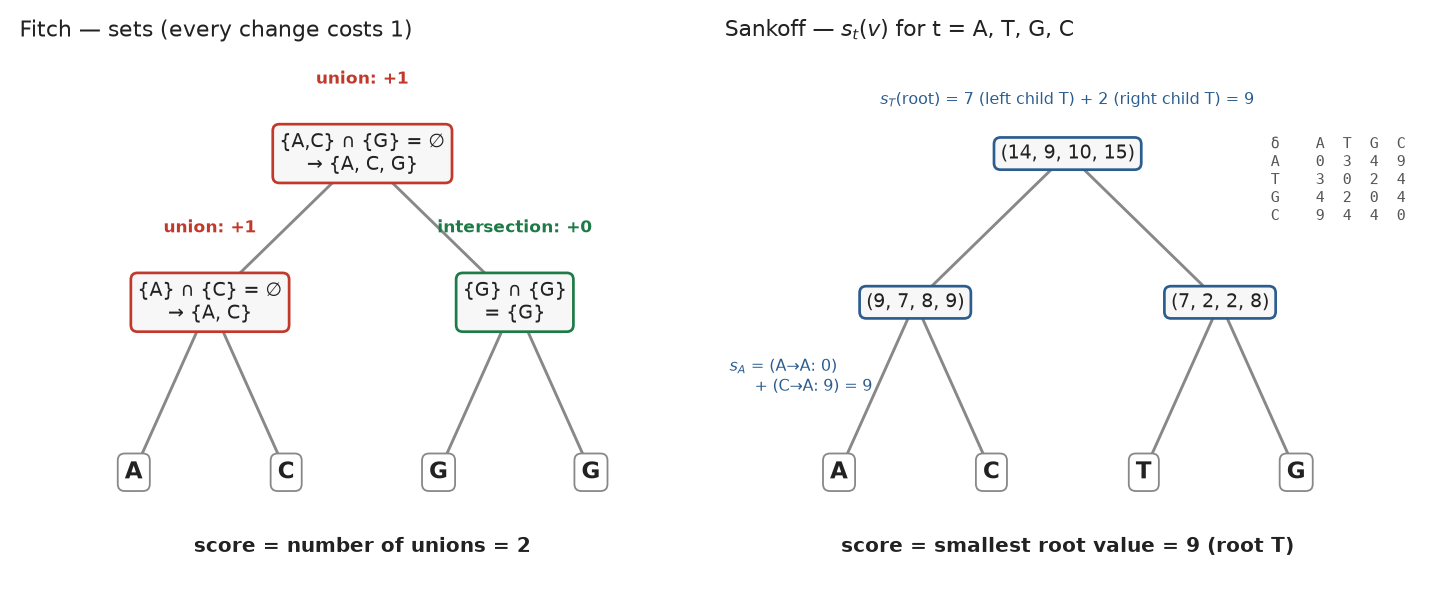

*To go further:* the lecture *Phylogenetic trees* (A. Carbone), **slides 63–92**,
works through both algorithms step by step. Two short written tutorials, each with
a worked example on a small primate + rodent tree (H. Ogilvie, Rice University):

- [Equal-cost parsimony](https://cs.rice.edu/~ogilvie/comp571/equal-cost-parsimony/)
  — Fitch's algorithm: sets, intersections and unions;
- [Unequal-cost parsimony](https://cs.rice.edu/~ogilvie/comp571/unequal-cost-parsimony/)
  — Sankoff's algorithm: a score matrix and one score per letter at each node.

**Signed permutation.** Cut two genomes into blocks of conserved order. Number the
blocks $1 \dots n$ by their order in one genome, then list them in their order in
the other genome, with a minus sign for a block in the opposite orientation. The
identity $1, 2, \dots, n$ means "same order, same orientation".

**Reversal** $\rho(i, j)$: reverse the order of the blocks at positions $i$ to $j$
and flip their signs. *Example:* $\rho(2, 3)$ turns $(1, -3, -2, 4)$ into
$(1, 2, 3, 4)$.

**Breakpoint.** Frame the permutation with $0$ in front and $n+1$ at the end. A
breakpoint is a pair of neighbours $(a, b)$ that is *not* $b = a + 1$. In
$(0, 1, -3, -2, 4, 5)$ the breakpoints are $(1, -3)$ and $(-2, 4)$; the pair
$(-3, -2)$ is not one, since $-2 = -3 + 1$. A reversal changes only the two neighbourhoods at its ends, so it removes **at most
two** breakpoints. The **reversal distance** is the smallest number of reversals
that turns the permutation into the identity.

***
# Exercise 1 — Parsimony

**Q1.1** What is the main idea of parsimony methods? Give an example.

**Q1.2** What are the *small* and the *large* parsimony problems? Which one is
harder, and why?

### &#9997;&#65039; Your answer — Q1.1 and Q1.2

_Double-click this cell and replace this line with your answer._

**Q1.3** What is the number of possible **unrooted** binary trees for $n$ species?
Justify your answer, then compute it for a few values of $n$ — including $n = 7$,
the number of species in Exercise 3, and $n = 50$.

In [ ]:
# ---- TODO ----
# Write a function n_unrooted(n) that returns the number of unrooted binary trees
# with n leaves, and print it for n = 3, 4, 5, 7, 10, 20 and 50.
# Python integers have no size limit, so the exact value is fine.

### &#9997;&#65039; Your answer — Q1.3

_Double-click this cell and replace this line with your answer._

**Q1.4** Given the sequences and the topology below, apply **Fitch's algorithm**
and **Sankoff's algorithm** to compute the parsimony score of the tree.

$$A = \texttt{ATCCTG} \qquad B = \texttt{ATCCGG} \qquad C = \texttt{ACGGCC} \qquad D = \texttt{AGGGCA}$$

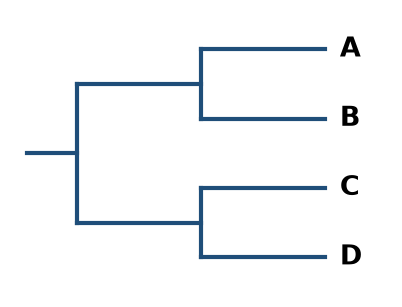

- **Fitch:** every substitution costs 1. Write the set of each internal node, site
  by site, and count the unions (step 1). Then give **one possible sequence for
  each internal node** (step 2), and check that it needs as many changes as your
  score.
- **Sankoff:** use the score matrix $\delta$ below (the lecture's). Write the
  scores $s_t(v)$ of each internal node, for $t$ = A, T, G, C, site by site.

| | **A** | **T** | **G** | **C** |
|---|:-:|:-:|:-:|:-:|
| **A** | 0 | 3 | 4 | 9 |
| **T** | 3 | 0 | 2 | 4 |
| **G** | 4 | 2 | 0 | 4 |
| **C** | 9 | 4 | 4 | 0 |

Do it **by hand** (on paper is fine — photograph it and embed the picture), then
check your two totals with `small_parsimony()`.

In [ ]:
# ---- TODO 1/2 : the hand computation ----
# Embed the photograph of your Fitch and Sankoff computations here, e.g.
# embed_image("ex1_parsimony.jpg", caption="Exercise 1 — Fitch and Sankoff by hand")

In [ ]:
# The data above, ready to use.
ex1_tree = "((A,B),(C,D));"
ex1_seqs = {"A": "ATCCTG", "B": "ATCCGG", "C": "ACGGCC", "D": "AGGGCA"}
sankoff_cost = pd.DataFrame([[0, 3, 4, 9],
                             [3, 0, 2, 4],
                             [4, 2, 0, 4],
                             [9, 4, 4, 0]],
                            index=list("ATGC"), columns=list("ATGC"))
sankoff_cost

In [ ]:
# ---- TODO 2/2 : check your totals ----
# small_parsimony(tree, sequences) scores the tree with unit costs (Fitch);
# small_parsimony(tree, sequences, cost) uses a score matrix (Sankoff).

### &#9997;&#65039; Your answer — Q1.4

_Double-click this cell and replace this line with your answer._

**Q1.5** What is the main idea of the **nearest neighbour interchange** (NNI)
algorithm? Why is it considered a *heuristic* method?

### &#9997;&#65039; Your answer — Q1.5

_Double-click this cell and replace this line with your answer._

***
# Exercise 2 — Reconstruction using reversal distances

We now compare **whole genomes**. Instead of substitutions in one gene, we look at
how large blocks of genes have been moved around: inverted in place (**inversions**,
the *reversals* of the lecture) or moved to another chromosome (**translocations**).

You will use NCBI's **Comparative Genome Viewer** (CGV),
<https://www.ncbi.nlm.nih.gov/cgv/>, which shows the alignment of two genome
assemblies. The assemblies used in this exercise:

- *Homo sapiens* (human) — **GRCh38.p14**
- *Mus musculus* (mouse) — **GRCm38.p6**
- *Anguilla japonica* (Japanese eel) — **ASM2516954v1**, in Q2.2 only

In CGV, **green** connections join regions aligned in the same orientation in both
genomes, **purple** ones regions aligned in opposite orientations. Each figure has
a download button; save it (SVG or PNG) next to this notebook, or take a
screenshot, and embed it with `embed_image()`.

**Q2.1** Open the **whole-genome** comparison of human and mouse and include the
figure. Keep the default *minimum alignment size* (**10 kb**). Look at human chromosome 1: onto how many mouse chromosomes is it spread?
What kind of rearrangement does that reveal, and what kind does the purple colour
reveal?

In [ ]:
# ---- TODO ----
# Embed your whole-genome figure, e.g.
# embed_image("cgv_human_mouse_genome.svg", caption="CGV — human vs mouse, whole genome")

### &#9997;&#65039; Your answer — Q2.1

_Double-click this cell and replace this line with your answer._

**Q2.2** Now open the **whole-genome** comparison of human with a much more distant
vertebrate, the **Japanese eel** (*Anguilla japonica*, assembly ASM2516954v1), with
the **same** minimum alignment size as in Q2.1 (the default, 10 kb). Include the
figure.

Compare it with the human–mouse figure of Q2.1: how much rearrangement do you see
(green and purple connections, how many eel chromosomes one human chromosome is
spread over)? Why? What does it mean for building trees from rearrangements between
distant species?

In [ ]:
# ---- TODO ----
# Embed your human vs Japanese eel whole-genome figure, e.g.
# embed_image("cgv_human_eel_genome.svg", caption="CGV — human vs Japanese eel, whole genome")

### &#9997;&#65039; Your answer — Q2.2

_Double-click this cell and replace this line with your answer._

**Q2.3** Now compare **chromosome 1 of human** with **chromosome 4 of mouse**
(click the chromosome in either genome, then choose the other one). In
*Adjust minimum alignment size*, set the minimum to **1 Mb** so that only the large
blocks remain. Include the figure.

Why is only **part** of each chromosome connected to the other? What does the
proportion of purple blocks tell you?

Finally, set the minimum alignment size back to the default **10 kb**. What happens
to the number of blocks, and so to the reversal distance you would compute from
them?

In [ ]:
# ---- TODO ----
# Embed your chromosome 1 (human) vs chromosome 4 (mouse) figure.

### &#9997;&#65039; Your answer — Q2.3

_Double-click this cell and replace this line with your answer._

**Q2.4 — Reversal distance by hand.** CGV shows the blocks but does not count the
rearrangements. We do it ourselves. The file `files/chr1_chr4_blocks_1Mb.txt`
holds the **signed permutation** read from the 1 Mb figure of Q2.3: the 19 blocks
are numbered by their order along mouse chromosome 4, listed in their order along
human chromosome 1, with a minus sign for a purple (inverted) block.

1. List the **breakpoints** of this permutation (by hand, then check with
   `breakpoints()`).
2. Using the fact that one reversal removes at most two breakpoints, give a
   **lower bound** on the reversal distance.
3. **Sort** the permutation with as few reversals as you can, applying them with
   `reverse(perm, i, j)` and printing each intermediate permutation.
4. Is your number of reversals the minimum? Check with `reversal_distance()`.

In [ ]:
perm_1Mb = read_permutation("files/chr1_chr4_blocks_1Mb.txt")
print(len(perm_1Mb), "blocks:", perm_1Mb)

In [ ]:
# ---- TODO ----
# 1. breakpoints(perm_1Mb)
# 2. Sort it: p = reverse(perm_1Mb, i, j); print(p); p = reverse(p, ...); ...
#    until p == list(range(1, 20)).
# 3. reversal_distance(perm_1Mb)

### &#9997;&#65039; Your answer — Q2.4

_Double-click this cell and replace this line with your answer._

**Q2.5** Whole-genome rearrangement distances between human, chimpanzee, mouse and
cow are given in `files/mammals4_matrix.txt` (displayed below).

1. These distances are not only reversal distances like the one of Q2.4. Given
   what you saw in Q2.1, which other rearrangements must they also count?
2. Build the **NJ** and the **UPGMA** tree from this matrix. Are these trees
   correct? Compare with the accepted phylogeny of placental mammals:

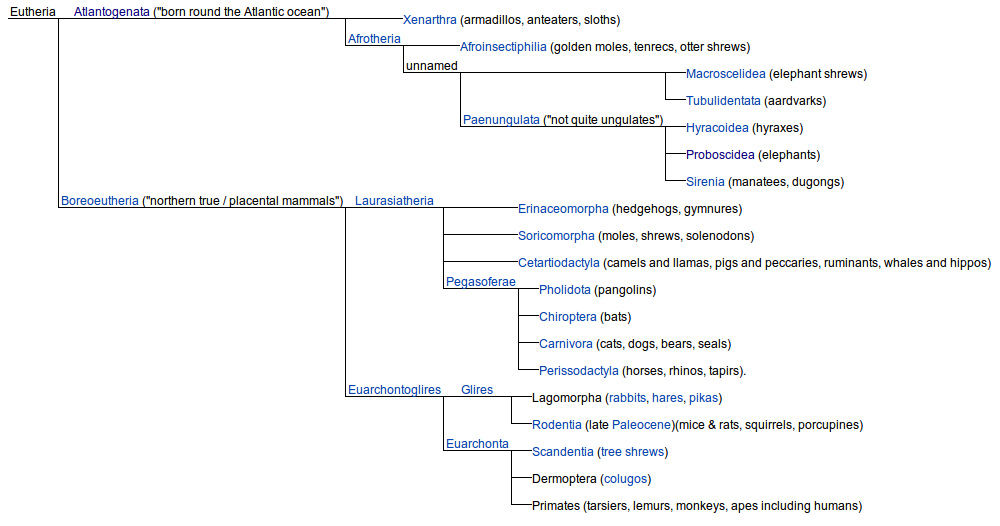

*The accepted tree of placental mammals (the opossum is not shown: it is a
marsupial, not a placental mammal).*

In [ ]:
four = read_phylip_matrix("files/mammals4_matrix.txt")
as_dataframe(four, decimals=0)

In [ ]:
# ---- TODO ----
# Build and show the NJ and the UPGMA tree from `four`.
# (show_tree draws NJ trees rooted at the midpoint; NJ itself is unrooted.)

### &#9997;&#65039; Your answer — Q2.5

_Double-click this cell and replace this line with your answer._

**Q2.6** Now use the **six mammals** of `files/mammals6_matrix.txt`. Compute both
trees: the NJ tree is **unrooted**, the UPGMA tree **rooted**. Are they correct?
What is the limitation of this approach?

> Instead of `show_tree()` you may draw the trees in [iTOL](https://itol.embl.de/upload.cgi):
> `save_newick(tree, "mammals_nj.nwk")` and upload the file. Embed a screenshot
> if you do.

In [ ]:
# ---- TODO ----
# Read files/mammals6_matrix.txt with read_phylip_matrix(), display it with
# as_dataframe(), then build and show both trees.

### &#9997;&#65039; Your answer — Q2.6

_Double-click this cell and replace this line with your answer._

***
# Exercise 3 — Reconstruction using characters

| | **Has placenta** | **Lives in water** | **Lays eggs** | **Single pair of incisors** | **Opposable thumb** | **Enlarged malleolus** |
|---|:-:|:-:|:-:|:-:|:-:|:-:|
| **Zebrafish** | No | Yes | Yes | No | No | No |
| **Opossum** | No | No | No | No | Yes | No |
| **Whale** | Yes | Yes | No | No | No | Yes |
| **Mouse** | Yes | No | No | Yes | No | Yes |
| **Rat** | Yes | No | No | Yes | No | Yes |
| **Chimp** | Yes | No | No | No | Yes | Yes |
| **Human** | Yes | No | No | No | Yes | Yes |

**Q3.1** What is the difference between **convergent** and **divergent** evolution?

### &#9997;&#65039; Your answer — Q3.1

_Double-click this cell and replace this line with your answer._

**Q3.2** Use PHYLIP's `pars` (through `parsimony_tree()`) on the matrix above to
compute a tree based on characters. Show it. Is it correct?

`pars` searches tree space with a heuristic (Q1.5). With only 7 species, all
945 unrooted trees can be scored: do it with `exhaustive_parsimony()`. Did `pars`
find every most parsimonious tree? Does that change your answer?

> Both functions return **unrooted** trees. To draw one, root it on the species you
> know to be the outgroup: `tree.root_with_outgroup("Zebrafish")`.

In [ ]:
# The table above, coded 1 = Yes, 0 = No (same as files/character_matrix.txt).
characters = pd.DataFrame(
    {"placenta":  [0, 0, 1, 1, 1, 1, 1],
     "water":     [1, 0, 1, 0, 0, 0, 0],
     "eggs":      [1, 0, 0, 0, 0, 0, 0],
     "incisors":  [0, 0, 0, 1, 1, 0, 0],
     "thumb":     [0, 1, 0, 0, 0, 1, 1],
     "malleolus": [0, 0, 1, 1, 1, 1, 1]},
    index=["Zebrafish", "Opossum", "Whale", "Mouse", "Rat", "Chimp", "Human"])
characters

In [ ]:
# ---- TODO 1/2 ----
# trees, steps = parsimony_tree(characters)
# How many trees, how many steps? Root and show the tree(s).

In [ ]:
# ---- TODO 2/2 ----
# all_best, best_steps = exhaustive_parsimony(characters)
# How many trees tie for the best score? Where is the opossum in each of them?
# (sister_group(tree, ["Opossum", "Human", "Mouse"]) helps.)

### &#9997;&#65039; Your answer — Q3.2

_Double-click this cell and replace this line with your answer._

**Q3.3** Run the analysis again **without the last column** (enlarged malleolus).
What happens? Which character is responsible for this incorrect tree?

In [ ]:
# ---- TODO ----
# characters.drop(columns="malleolus") gives the table without the last column.
# Run pars, and the exhaustive search, on it.

### &#9997;&#65039; Your answer — Q3.3

_Double-click this cell and replace this line with your answer._

**Q3.4** The presence of a character in two species can be explained either by a
**common ancestor** or by **convergent evolution**. Find all cases of convergent
evolution in the table.

### &#9997;&#65039; Your answer — Q3.4

_Double-click this cell and replace this line with your answer._

***
## References

1. Hannenhalli, S. & Pevzner, P. A. "Transforming cabbage into turnip: polynomial
   algorithm for sorting signed permutations by reversals." *Proceedings of STOC*
   (1995) — the algorithm behind `reversal_distance()`.